In [13]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import glob as gb
from tqdm import tqdm
import cv2


In [14]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("akshitmadan/eyes-open-or-closed")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'eyes-open-or-closed' dataset.
Path to dataset files: /kaggle/input/eyes-open-or-closed


In [15]:
path

'/kaggle/input/eyes-open-or-closed'

In [16]:
import os

In [17]:
os.listdir(path+"/"+'dataset')

['test', 'train']

In [18]:
train_dir = path+"/"+'dataset/train'
test_dir = path+"/"+'dataset/test'

In [19]:
train_dir

'/kaggle/input/eyes-open-or-closed/dataset/train'

In [20]:

os.listdir(train_dir)

['Open_Eyes', 'Closed_Eyes']

In [21]:
os.listdir(test_dir)

['Open_Eyes', 'Closed_Eyes']

In [22]:
x_train = []
y_train = []
for folder in os.listdir(train_dir):
    print(folder)
    for file in tqdm(gb.glob(train_dir+"/"+folder+"/*.png")):
        img = cv2.imread(file)
        img = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
        img = cv2.resize(img,(224,224))
        img = img / 255.0
        x_train.append(img)
        y_train.append(folder)



Open_Eyes


100%|██████████| 1640/1640 [00:02<00:00, 755.40it/s]


Closed_Eyes


100%|██████████| 1760/1760 [00:02<00:00, 759.05it/s]


In [23]:
len(x_train)

3400

In [24]:
x_train = np.array(x_train)
x_train = x_train.reshape(x_train.shape[0], x_train.shape[1], x_train.shape[2], 1)

In [25]:
x_train.shape

(3400, 224, 224, 1)

In [26]:
y_train = np.array(y_train)

In [27]:
np.random.randint(0,x_train.shape[0],16)

array([3245, 3072, 1308,  698, 2191,  488, 2128, 2845, 3132, 1616, 2384,
       1785,  107,  546, 2960,  659])

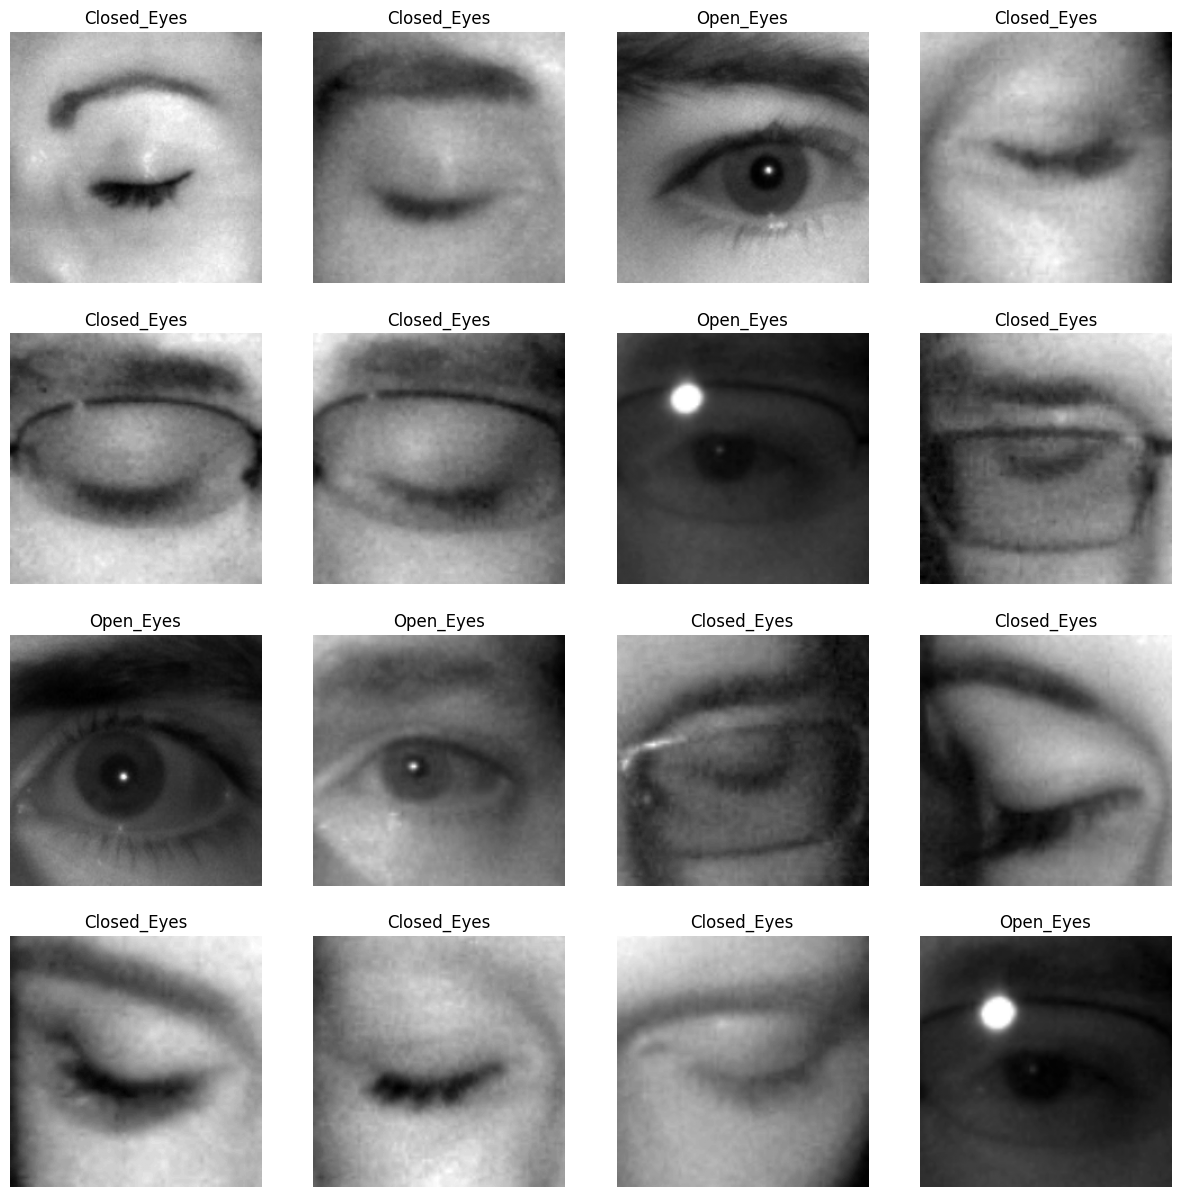

In [29]:
plt.figure(figsize=(15,15))
for ind in enumerate(np.random.randint(0,x_train.shape[0],16)):
    plt.subplot(4,4,ind[0]+1)
    plt.imshow(x_train[ind[1]],cmap='gray')
    plt.title(y_train[ind[1]])
    plt.axis('off')

In [30]:
x_test = []
y_test = []

for folder in os.listdir(test_dir):
  print(folder)
  for file in tqdm(gb.glob(test_dir+"/"+folder+"/*.png")):
        img = cv2.imread(file)
        img = cv2.resize(img,(224,224))
        cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
        x_test.append(img)
        img = img/255.0
        y_test.append(folder)

Open_Eyes


100%|██████████| 360/360 [00:01<00:00, 280.89it/s]


Closed_Eyes


100%|██████████| 240/240 [00:00<00:00, 287.58it/s]


In [31]:
x_test = np.array(x_test)
y_test = np.array(y_test)

In [32]:
np.random.randint(0,x_test.shape[0],16)

array([465, 555, 141, 391, 488, 415,  69, 334, 320, 572, 259,  93, 297,
       333, 476, 387])

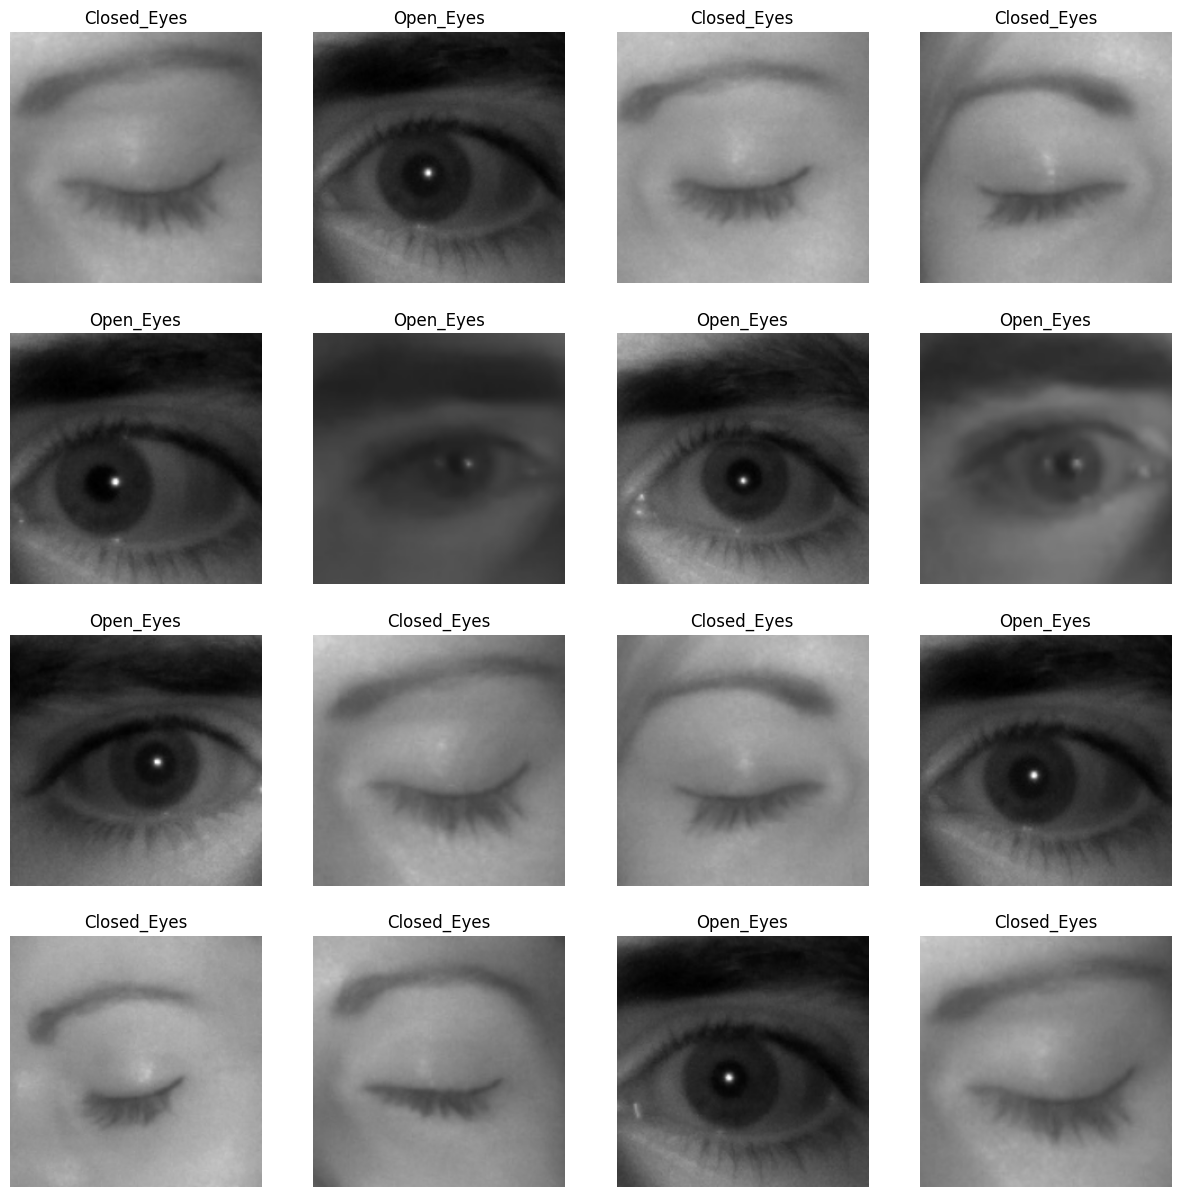

In [33]:
plt.figure(figsize=(15,15))
for ind in enumerate(np.random.randint(0,x_test.shape[0],16)):
    plt.subplot(4,4,ind[0]+1)
    plt.imshow(x_test[ind[1]])
    plt.title(y_test[ind[1]])
    plt.axis('off')

In [34]:
from sklearn.utils import shuffle

In [36]:
x_train,y_train = shuffle(x_train,y_train)

<Axes: xlabel='count'>

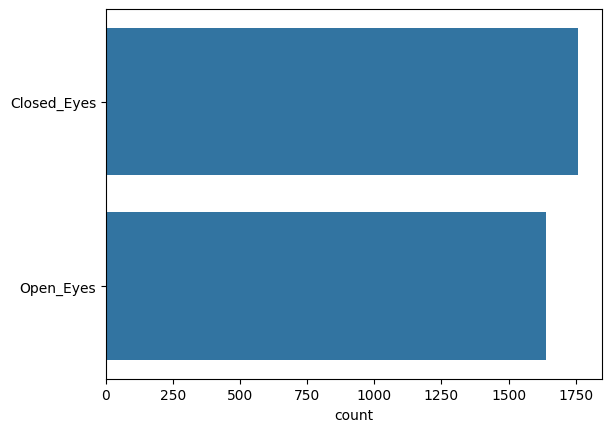

In [37]:
sns.countplot(y_train)

<Axes: xlabel='count'>

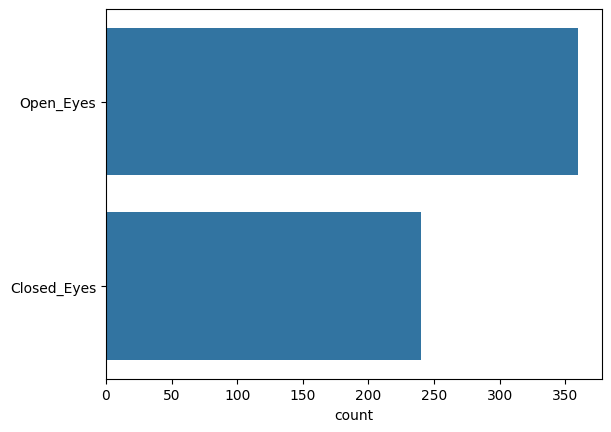

In [38]:
sns.countplot(y_test)

In [39]:
from sklearn.preprocessing import LabelEncoder

In [40]:
lb=LabelEncoder()

In [41]:
y_train = lb.fit_transform(y_train)
y_test=lb.transform(y_test)

In [42]:
y_train[ : 5]

array([0, 0, 0, 1, 0])

In [43]:
lb.classes_

array(['Closed_Eyes', 'Open_Eyes'], dtype='<U11')

In [44]:


from sklearn.model_selection import train_test_split
x_train,x_val,y_train,y_val = train_test_split(x_train,y_train,test_size=0.1,random_state=42,stratify=y_train,
                                               shuffle=True)




In [45]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,Dropout

In [51]:


model = Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(224,224,1)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.2),


    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(1,activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [52]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,513 (42.60 MB)

 Trainable params: 11,168,513 (42.60 MB)

 Non-trainable params: 0 (0.00 B)

In [53]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [54]:

from functools import reduce
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.001,
    patience=3,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
)
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_model.h5",
    monitor="val_loss",
    verbose=1,
    save_best_only=True,
    save_weights_only=False,
    mode="auto",
    save_freq="epoch",
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=2,
    verbose=1,
    mode="auto",
    min_delta=0.0001,
    cooldown=0,
    min_lr=0,
)

In [55]:
from itertools import batched
history = model.fit(x_train,y_train,
                    batch_size=32,
                    epochs=20,
                    callbacks=[early_stopping,model_checkpoint,reduce_lr],
                    validation_data=(x_val,y_val))

Epoch 1/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.7381 - loss: 0.5310
Epoch 1: val_loss improved from None to 0.05952, saving model to best_model.h5



Epoch 1: finished saving model to best_model.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 24s 143ms/step - accuracy: 0.8585 - loss: 0.3067 - val_accuracy: 0.9676 - val_loss: 0.0595 - learning_rate: 0.0010
Epoch 2/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9707 - loss: 0.0791
Epoch 2: val_loss improved from 0.05952 to 0.03875, saving model to best_model.h5



Epoch 2: finished saving model to best_model.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.9683 - loss: 0.0909 - val_accuracy: 0.9912 - val_loss: 0.0387 - learning_rate: 0.0010
Epoch 3/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9851 - loss: 0.0512
Epoch 3: val_loss improved from 0.03875 to 0.03285, saving model to best_model.h5



Epoch 3: finished saving model to best_model.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.9850 - loss: 0.0441 - val_accuracy: 0.9912 - val_loss: 0.0328 - learning_rate: 0.0010
Epoch 4/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9865 - loss: 0.0412
Epoch 4: val_loss improved from 0.03285 to 0.02501, saving model to best_model.h5



Epoch 4: finished saving model to best_model.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.9876 - loss: 0.0401 - val_accuracy: 0.9912 - val_loss: 0.0250 - learning_rate: 0.0010
Epoch 5/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9928 - loss: 0.0233
Epoch 5: val_loss did not improve from 0.02501
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9931 - loss: 0.0215 - val_accuracy: 0.9941 - val_loss: 0.0251 - learning_rate: 0.0010
Epoch 6/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9935 - loss: 0.0174
Epoch 6: val_loss improved from 0.02501 to 0.01700, saving model to best_model.h5



Epoch 6: finished saving model to best_model.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.9944 - loss: 0.0168 - val_accuracy: 0.9971 - val_loss: 0.0170 - learning_rate: 0.0010
Epoch 7/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9980 - loss: 0.0054
Epoch 7: val_loss improved from 0.01700 to 0.00279, saving model to best_model.h5



Epoch 7: finished saving model to best_model.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.9990 - loss: 0.0035 - val_accuracy: 0.9971 - val_loss: 0.0028 - learning_rate: 0.0010
Epoch 8/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9999 - loss: 5.7610e-04
Epoch 8: val_loss improved from 0.00279 to 0.00102, saving model to best_model.h5



Epoch 8: finished saving model to best_model.h5
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.9987 - loss: 0.0022 - val_accuracy: 1.0000 - val_loss: 0.0010 - learning_rate: 0.0010
Epoch 9/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9988 - loss: 0.0076
Epoch 9: val_loss did not improve from 0.00102
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9961 - loss: 0.0171 - val_accuracy: 0.9941 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 10/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9946 - loss: 0.0168
Epoch 10: val_loss did not improve from 0.00102

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9967 - loss: 0.0105 - val_accuracy: 0.9941 - val_loss: 0.0195 - learning_rate: 0.0010
Epoch 11/20
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.9983 - loss: 0.0049
Epoch 11: val_loss did not improve from 0.00102
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 

In [56]:
history.history

{'accuracy': [0.8584967255592346,
  0.9683006405830383,
  0.9849672913551331,
  0.9875816702842712,
  0.9931372404098511,
  0.9944444298744202,
  0.9990196228027344,
  0.9986928105354309,
  0.9960784316062927,
  0.9967319965362549,
  0.9996731877326965],
 'loss': [0.30672264099121094,
  0.09090423583984375,
  0.044065382331609726,
  0.04010608792304993,
  0.021496932953596115,
  0.01680559292435646,
  0.003503900719806552,
  0.002214290201663971,
  0.017060812562704086,
  0.010499700903892517,
  0.00214621820487082],
 'val_accuracy': [0.9676470756530762,
  0.9911764860153198,
  0.9911764860153198,
  0.9911764860153198,
  0.9941176176071167,
  0.9970588088035583,
  0.9970588088035583,
  1.0,
  0.9941176176071167,
  0.9941176176071167,
  0.9970588088035583],
 'val_loss': [0.05952000245451927,
  0.03874918818473816,
  0.032848458737134933,
  0.025010379031300545,
  0.025121789425611496,
  0.01699833944439888,
  0.0027877697721123695,
  0.0010226364247500896,
  0.008983075618743896,
  0.01

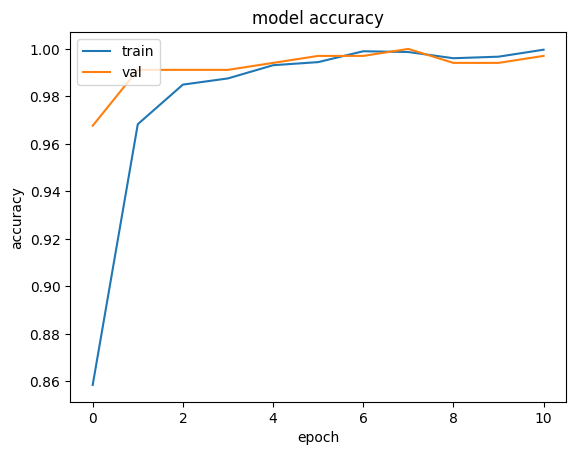

In [57]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')

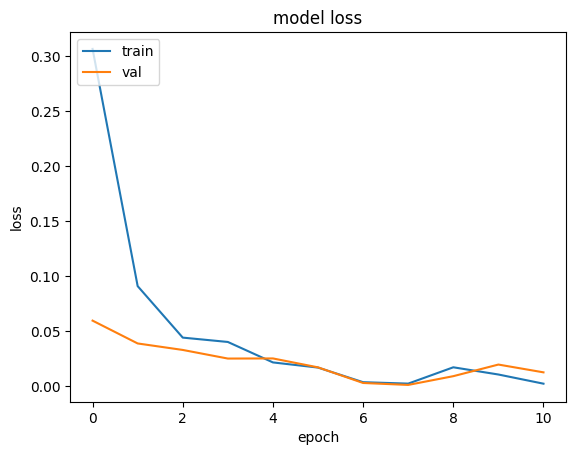

In [58]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')

In [59]:
model.evaluate(x_train,y_train)

96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 1.0000 - loss: 7.9544e-04


[0.0007954405737109482, 1.0]

In [63]:
x_test_gray = np.array([cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in x_test])
x_test_gray = x_test_gray / 255.0
x_test_gray = x_test_gray.reshape(x_test_gray.shape[0], 224, 224, 1)

y_pred = model.predict(x_test_gray)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


In [64]:
y_pred = y_pred.round()

In [65]:
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score,precision_score,recall_score,f1_score

In [66]:
cm = confusion_matrix(y_test,y_pred)

<Axes: >

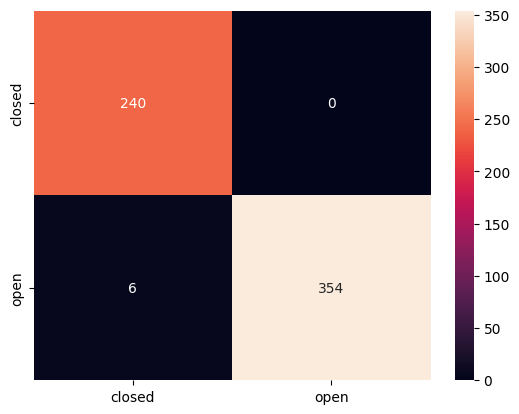

In [67]:
sns.heatmap(cm,annot=True,fmt='d',xticklabels=['closed','open'],yticklabels=['closed','open'])

In [69]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       240
           1       1.00      0.98      0.99       360

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



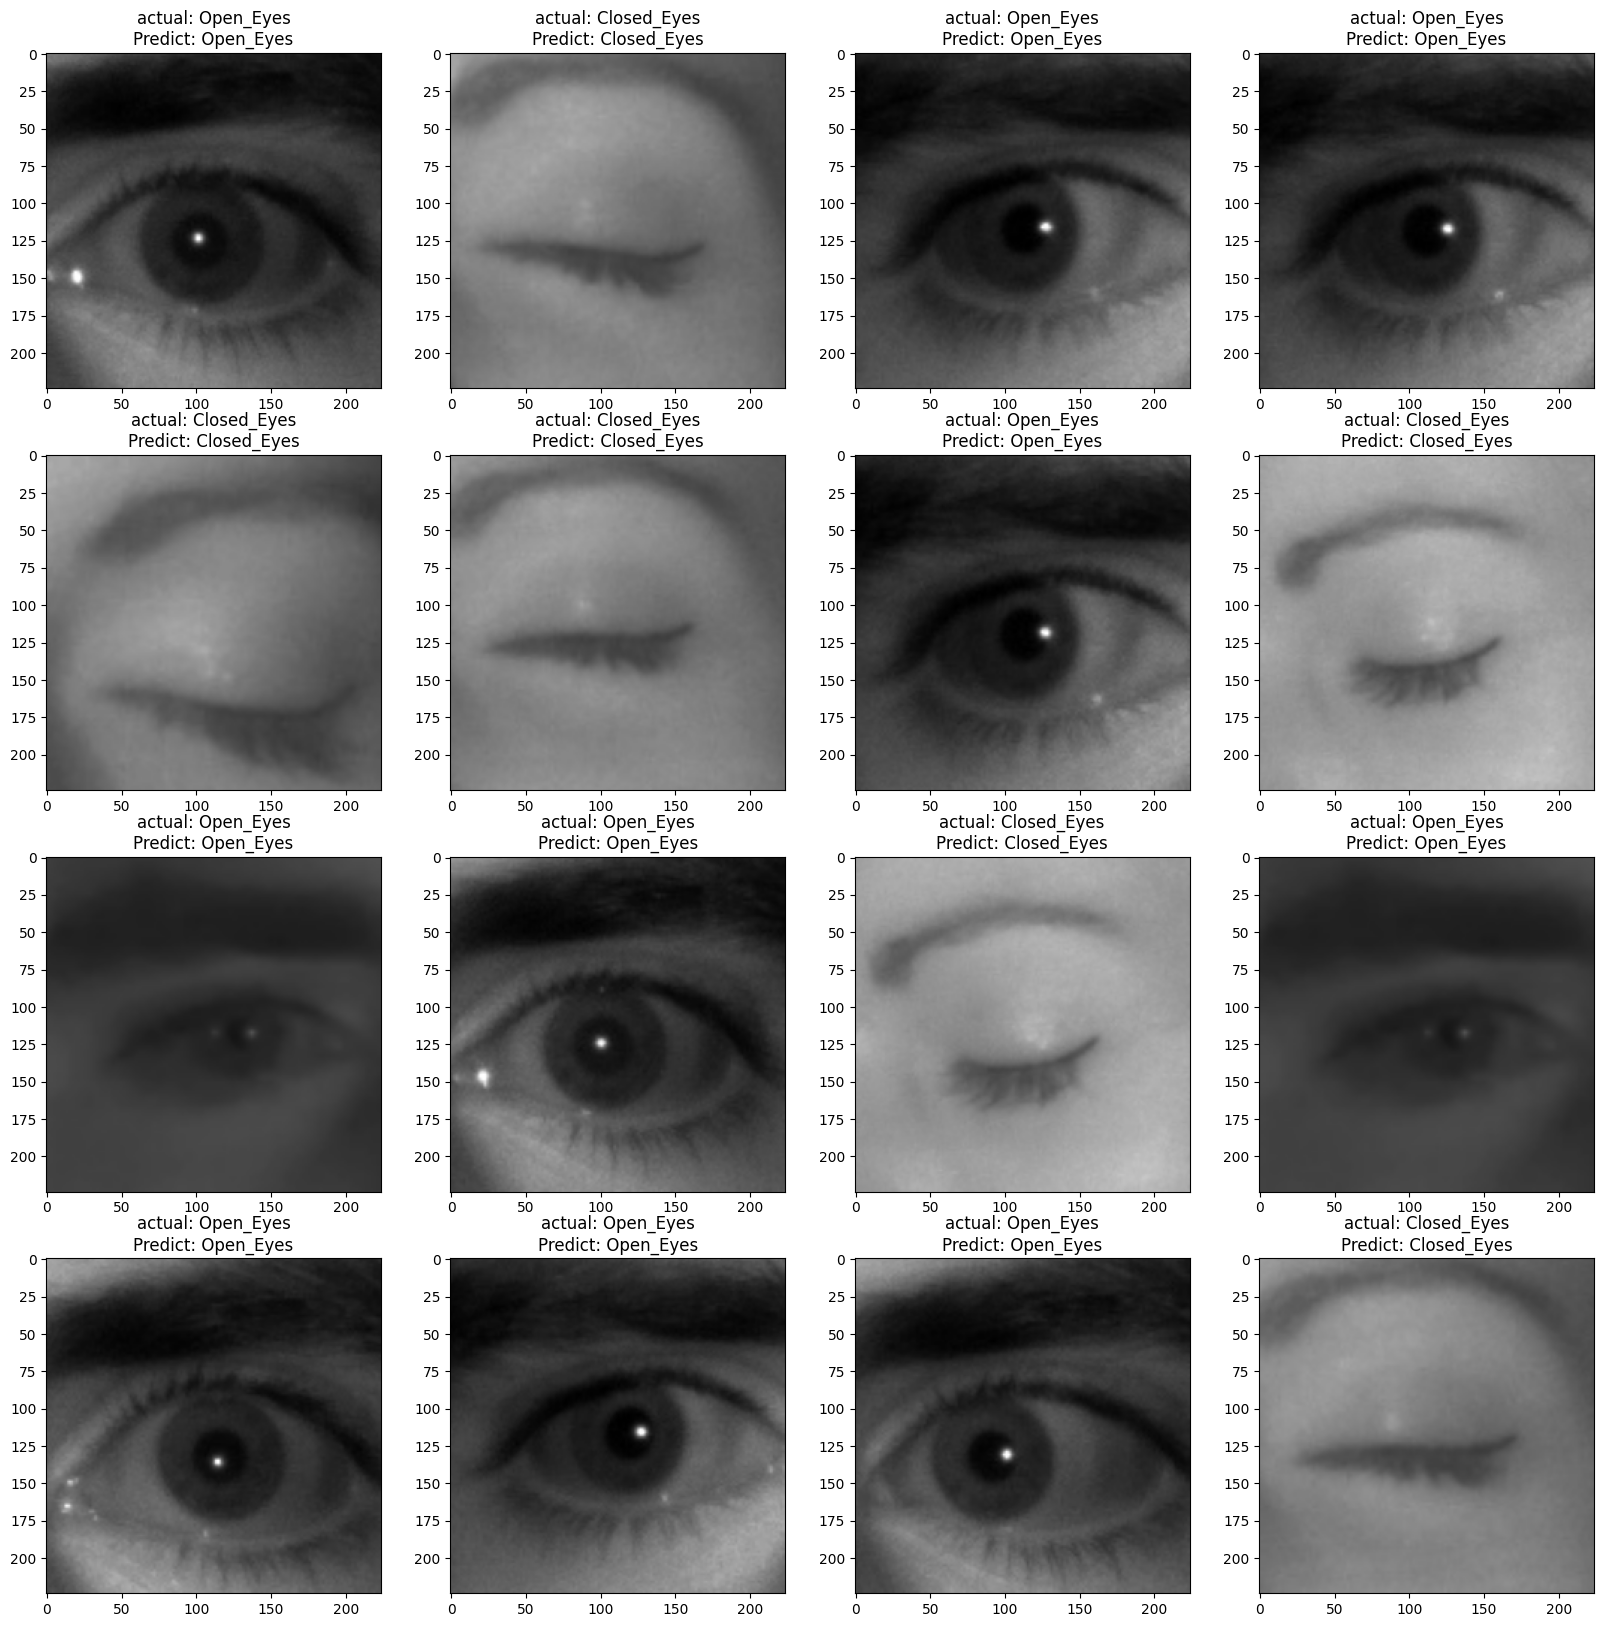

In [70]:
classes= ['Closed_Eyes', 'Open_Eyes']
plt.figure(figsize=(20,20))
for ind , n in enumerate(np.random.randint(0,x_test.shape[0],16)):
    plt.subplot(4,4,ind+1)
    plt.imshow(x_test[n],cmap='gray')

    plt.title("actual: "+str(classes[y_test[n]])+\
              "\nPredict: " +str(classes[int(y_pred[n][0])]))